# 03 Attribution: where does the difference against the 60/40 come from?

Notebook 02 showed that momentum and the 60/40 ended with similar returns, but with very different paths. This notebook explains the difference with a **Brinson-Fachler attribution by asset class**.

Each month, the strategy's return minus the benchmark's return (the *active return*) is split into:

| Effect | Question it answers | Formula (per asset class *i*) |
|---|---|---|
| **Allocation** | Did over- or underweighting an asset class help? | (w<sub>p</sub> − w<sub>b</sub>) × (r<sub>b,i</sub> − R<sub>b</sub>) |
| **Selection** | Did choosing different ETFs *within* a class help (e.g. EEM instead of SPY, TLT instead of IEF)? | w<sub>p</sub> × (r<sub>p,i</sub> − r<sub>b,i</sub>) |
| **Trading costs** | How much did implementation cost? | − turnover × cost |

*w* = weight, *r* = return of the class, *R<sub>b</sub>* = total benchmark return, *p* = portfolio (momentum), *b* = benchmark (60/40).
Selection here includes the interaction term (a common presentation that keeps two effects instead of three).

**Asset classes**

| Class | Strategy can hold | Benchmark return used for the class |
|---|---|---|
| Equity | SPY, EFA, EEM | SPY |
| Bonds | IEF, TLT | IEF |
| Real assets | GLD, VNQ | 50/50 GLD + VNQ (the 60/40 holds none, so a neutral mix is needed) |
| Cash | uninvested weight | 0% (cash earns no interest in this backtest) |

The benchmark weights are 60% equity, 40% bonds, 0% real assets, 0% cash.

In [1]:
# Run once if yfinance is not installed yet (then restart the kernel):
# %pip install -q yfinance

In [2]:
import sys
sys.path.insert(0, "..")   # lets the notebook find the src/ folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.backtest import *
from src.attribution import (
    ASSET_CLASSES, CASH, class_weights, attribution_report, carino_link,
)

FIGURES = "../reports/figures"

## 1. Run the backtest and build the inputs

In [3]:
res = run_comparison()
strategy, bench = res["strategy"], res["bench"]
months = strategy.index

returns = res["prices"].pct_change().loc[months]
held = res["weights"].shift(1).loc[months]              # weights actually held each month
costs = (res["turnover"] * COST_BPS / 10_000).loc[months]

bench_w = pd.DataFrame(0.0, index=months, columns=held.columns)
for ticker, w in BENCHMARK.items():
    bench_w[ticker] = w

Loaded 262 months of real data (2005-01 to 2026-10)
Period: 2006-03-31 to 2026-10-31 (248 months)


## 2. Average weights by asset class

Context for the allocation effect: how differently did the strategy invest compared with the 60/40?

In [4]:
avg_w = pd.DataFrame({
    "Momentum": class_weights(held).mean(),
    "60/40": class_weights(bench_w).mean(),
})
avg_w["Difference"] = avg_w["Momentum"] - avg_w["60/40"]
avg_w = avg_w.loc[["Equity", "Bonds", "Real assets", CASH]]
print(avg_w.map(lambda x: f"{x:6.1%}").to_string())

            Momentum   60/40 Difference
Ticker                                 
Equity         44.6%   60.0%     -15.4%
Bonds          16.1%   40.0%     -23.9%
Real assets    33.7%    0.0%      33.7%
Cash            5.5%    0.0%       5.5%


## 3. Monthly attribution and reconciliation check

The monthly effects must add up exactly to the monthly active return. If this check fails, something is wrong.

In [5]:
summary_linked, effects, check = attribution_report(held, bench_w, returns, costs)

# Fold interaction into selection (see the table at the top)
eff = pd.DataFrame(index=months)
for cls in ["Equity", "Bonds", "Real assets", CASH]:
    eff[("Allocation", cls)] = effects[("Allocation", cls)]
    eff[("Selection", cls)] = effects[("Selection", cls)] + effects[("Interaction", cls)]
eff[("Trading costs", "Total")] = effects[("Trading costs", "Total")]
eff.columns = pd.MultiIndex.from_tuples(eff.columns)

monthly_active = strategy - bench
gap = (eff.sum(axis=1) - monthly_active).abs().max()
print(f"Largest monthly gap between effects and active return: {gap:.2e}")
assert gap < 1e-10, "Attribution does not reconcile with the backtest"
print("Reconciliation OK: the effects add up to the active return every month.")

Largest monthly gap between effects and active return: 1.39e-17
Reconciliation OK: the effects add up to the active return every month.


## 4. Average annual contribution by asset class

Each number is the average contribution to the active return, in percentage points per year (arithmetic: average monthly effect × 12). The total equals the annualised active return reported in notebook 02.

In [6]:
annual = eff.mean() * 12

table = pd.DataFrame({
    "Allocation": annual["Allocation"],
    "Selection": annual["Selection"],
}).loc[["Equity", "Bonds", "Real assets", CASH]]
table["Total"] = table.sum(axis=1)
table.loc["Trading costs"] = [np.nan, np.nan, annual[("Trading costs", "Total")]]
table.loc["Total"] = table.sum()

print("Average annual contribution to active return (percentage points)")
print(table.map(lambda x: "" if pd.isna(x) else f"{x * 100:+6.2f}").to_string())
print(f"\nAnnualised active return (check): {monthly_active.mean() * 12:+.2%}")

Average annual contribution to active return (percentage points)
              Allocation Selection   Total
Equity             -0.44     -1.33   -1.77
Bonds              +1.35     +0.23   +1.58
Real assets        +0.11     +1.16   +1.27
Cash               -0.70     +0.00   -0.70
Trading costs                        -0.32
Total              +0.32     +0.06   +0.06

Annualised active return (check): +0.06%


Chart saved to ../reports/figures/attribution_by_class.png


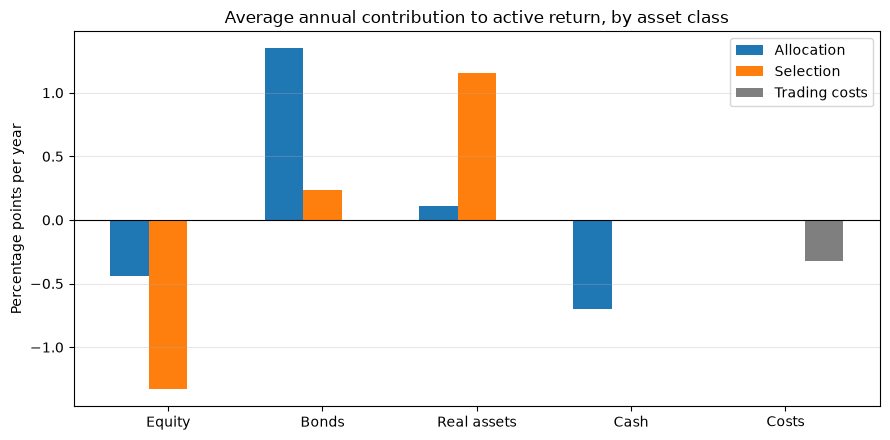

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_rows = ["Equity", "Bonds", "Real assets", CASH]
x = np.arange(len(plot_rows) + 1)
alloc = list(table.loc[plot_rows, "Allocation"] * 100) + [0]
select = list(table.loc[plot_rows, "Selection"] * 100) + [0]
costs_bar = [0] * len(plot_rows) + [table.loc["Trading costs", "Total"] * 100]

ax.bar(x - 0.25, alloc, width=0.25, label="Allocation")
ax.bar(x, select, width=0.25, label="Selection")
ax.bar(x + 0.25, costs_bar, width=0.25, label="Trading costs", color="tab:gray")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(plot_rows + ["Costs"])
ax.set_ylabel("Percentage points per year")
ax.set_title("Average annual contribution to active return, by asset class")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_figure(fig, f"{FIGURES}/attribution_by_class.png")
plt.show()

## 5. Attribution by calendar year

Within each year, the monthly effects are linked with the **Carino method**, so each year's effects add up exactly to that year's return difference (the *Difference* column in notebook 02).

In [8]:
by_effect = eff.T.groupby(level=0).sum().T          # Allocation, Selection, Trading costs

rows = {}
for year, idx in by_effect.groupby(by_effect.index.year).groups.items():
    linked = carino_link(by_effect.loc[idx], strategy.loc[idx], bench.loc[idx])
    rows[year] = linked
yearly_attr = pd.DataFrame(rows).T[["Allocation", "Selection", "Trading costs"]]
yearly_attr["Total"] = yearly_attr.sum(axis=1)

# Check against the calendar-year return difference
yearly_diff = ((1 + strategy).groupby(strategy.index.year).prod()
               - (1 + bench).groupby(bench.index.year).prod())
assert (yearly_attr["Total"] - yearly_diff).abs().max() < 1e-10

months_per_year = strategy.groupby(strategy.index.year).size()
yearly_attr.index = [f"{y}*" if months_per_year[y] < 12 else str(y) for y in yearly_attr.index]

print("Attribution by calendar year (percentage points, * = partial year)")
print(yearly_attr.map(lambda x: f"{x * 100:+6.1f}").to_string())

Attribution by calendar year (percentage points, * = partial year)
      Allocation Selection Trading costs   Total
2006*       +8.5      -3.4          -0.4    +4.7
2007        -5.3     +10.6          -0.4    +4.9
2008       +12.7     +12.4          -0.2   +25.0
2009       -11.2      +1.6          -0.3    -9.9
2010        +3.3      -6.6          -0.5    -3.8
2011        -4.2      -7.0          -0.5   -11.8
2012        -4.7      -1.2          -0.4    -6.2
2013        -0.5      +1.8          -0.2    +1.1
2014        +4.0      -0.3          -0.2    +3.5
2015        -3.5      +0.6          -0.2    -3.1
2016        -6.7      -6.5          -0.6   -13.8
2017        +7.6      +5.2          -0.2   +12.5
2018        +5.9     -10.4          -0.1    -4.7
2019        -3.8      +5.3          -0.6    +0.9
2020       -15.7      +5.5          -0.6   -10.8
2021        +6.9     -12.8          -0.4    -6.3
2022        +0.8      -0.3          -0.2    +0.3
2023        -2.7      +0.3          -0.3    -2.7
20

Chart saved to ../reports/figures/attribution_by_year.png


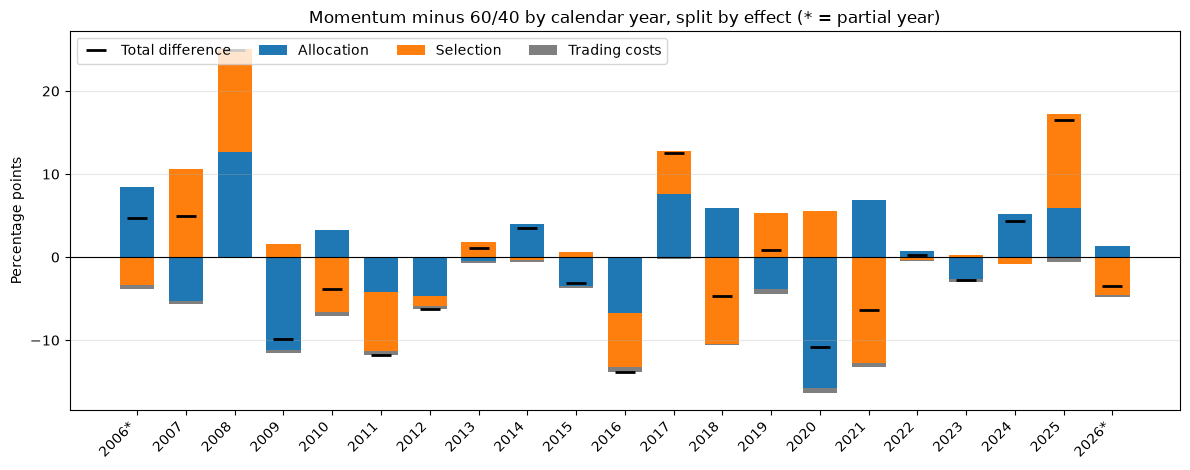

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.8))
x = np.arange(len(yearly_attr))
pos_base = np.zeros(len(x))
neg_base = np.zeros(len(x))
colors = {"Allocation": "tab:blue", "Selection": "tab:orange", "Trading costs": "tab:gray"}

for col in ["Allocation", "Selection", "Trading costs"]:
    vals = yearly_attr[col].values * 100
    base = np.where(vals >= 0, pos_base, neg_base)
    ax.bar(x, vals, bottom=base, label=col, color=colors[col], width=0.7)
    pos_base += np.where(vals >= 0, vals, 0)
    neg_base += np.where(vals < 0, vals, 0)

ax.plot(x, yearly_attr["Total"].values * 100, "k_", markersize=14, mew=2, label="Total difference")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(yearly_attr.index, rotation=45, ha="right")
ax.set_ylabel("Percentage points")
ax.set_title("Momentum minus 60/40 by calendar year, split by effect (* = partial year)")
ax.legend(ncol=4, loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_figure(fig, f"{FIGURES}/attribution_by_year.png")
plt.show()

## 6. What drove the best and worst years?

Total effect (allocation + selection) by asset class, for the years with the largest differences against the 60/40.

In [10]:
by_class = eff.drop(columns=("Trading costs", "Total")).T.groupby(level=1).sum().T
by_class["Trading costs"] = eff[("Trading costs", "Total")]

year_tables = {}
for year, idx in by_class.groupby(by_class.index.year).groups.items():
    year_tables[year] = carino_link(by_class.loc[idx], strategy.loc[idx], bench.loc[idx])
class_by_year = pd.DataFrame(year_tables).T[["Equity", "Bonds", "Real assets", CASH, "Trading costs"]]
class_by_year["Total"] = class_by_year.sum(axis=1)

full_years = [y for y in class_by_year.index if months_per_year[y] == 12]
ranked = class_by_year.loc[full_years, "Total"].sort_values()
key_years = list(ranked.index[-3:][::-1]) + list(ranked.index[:3])

print("Best and worst full years: contribution by asset class (percentage points)")
print(class_by_year.loc[key_years].map(lambda x: f"{x * 100:+6.1f}").to_string())

Best and worst full years: contribution by asset class (percentage points)
      Equity   Bonds Real assets    Cash Trading costs   Total
2008    +9.6    +9.3        +6.9    -0.8          -0.2   +25.0
2025    +2.6    +2.5       +12.0    +0.0          -0.6   +16.6
2017    +7.2    +4.9        +0.7    +0.0          -0.2   +12.5
2016    -6.1    +1.2        -5.7    -2.6          -0.6   -13.8
2011    -4.9    -1.8        -4.5    +0.0          -0.5   -11.8
2020    -4.6    -6.1        +0.5    +0.0          -0.6   -10.8
